# GridLeak AI — Model Eğitimi ve SMOTE Karşılaştırması

Mevcut master defterin hücreleri içerikleri ve kayıtlı çıktıları korunarak bu deftere taşınmıştır. Ortak hazırlık hücreleri bağımsız açılış için tekrar yer alır.

Bu düzenleme yeni eğitim veya değerlendirme çalıştırmamıştır. Hücreleri çalıştırmak ilgili hesaplamaları yeniden yürütür.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, average_precision_score, roc_auc_score, f1_score,
    precision_score, recall_score, precision_recall_curve, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay
)
warnings.filterwarnings('ignore')

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ai/features/v3_features.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Projedeki GERÇEK üretim modüllerini doğrudan içe aktarıyoruz (sıfır kod tekrarı!)
from ai.features.v3_features import load_raw_for_ids, extract_subscriber_features, FoldContextTransformer
from ai.training.v3_final_train_and_test import build_base_estimators, build_meta_estimator, ece_score

EXP = ROOT / 'ai/artifacts/iyilestirme_v3_20261123T171349Z'
V3 = ROOT / 'data/processed/v3'
lock = json.loads((EXP / 'locked_selection.json').read_text(encoding='utf-8'))
fcols = lock['features']
print('Proje Kökü:', ROOT)
print('Aktif Kilitli Model:', lock['model_name'])
print('Kilitli Özellik Sayısı:', len(fcols))

Proje Kökü: c:\Users\kadir\GridLeakAI
Aktif Kilitli Model: Calibrated Stacking v3 (LGBM + CatBoost + XGBoost + MLP)
Kilitli Özellik Sayısı: 160


## 1. Veri Seti Yapısı, %80/%20 Abone Bölünmesi ve Sınıf Dengesizliği
Aboneler kimlik (`CONS_NO`) bazında tabakalı bölünmüştür; eğitim ve test arasında **sıfır ortak abone** vardır.

In [2]:
train_df = pd.read_csv(V3 / 'egitim_ozellikleri_2016_v1.csv', dtype={'CONS_NO': str})
test_df = pd.read_csv(V3 / 'test_ozellikleri_2016_v1.csv', dtype={'CONS_NO': str})
test_y_df = pd.read_csv(V3 / 'test_hedefleri_2016_v1.csv', dtype={'CONS_NO': str}).set_index('CONS_NO')
assert not (set(train_df['CONS_NO']) & set(test_df['CONS_NO'])), 'Eğitim/Test sızıntısı!'

y_tr = train_df['FLAG'].to_numpy(int)
y_te = test_y_df.loc[test_df['CONS_NO'], 'FLAG'].to_numpy(int)
print(f'Eğitim: {len(train_df):,} abone | FLAG=0: {(y_tr==0).sum():,} (%{(y_tr==0).mean()*100:.2f}) | FLAG=1: {(y_tr==1).sum():,} (%{y_tr.mean()*100:.2f})')
print(f'Test  : {len(test_df):,} abone | FLAG=0: {(y_te==0).sum():,} (%{(y_te==0).mean()*100:.2f}) | FLAG=1: {(y_te==1).sum():,} (%{y_te.mean()*100:.2f})')
print('Eğitim-Test Ortak Abone Sayısı: 0')

Eğitim: 33,858 abone | FLAG=0: 30,996 (%91.55) | FLAG=1: 2,862 (%8.45)
Test  : 8,466 abone | FLAG=0: 7,748 (%91.52) | FLAG=1: 718 (%8.48)
Eğitim-Test Ortak Abone Sayısı: 0


## 3. Sınıf Dengesizliği: Gerçek Kat-İçi SMOTE vs. Doğal Dağılım Kıyaslaması
SMOTE (`sampling_strategy=0.5`) yalnızca CV eğitim katları içinde (`imblearn.pipeline.Pipeline`, doğrulama katına sıfır sentetik örnek!) uygulanarak 3 farklı model ailesinde doğal dağılımla birebir kıyaslanır.

,Model / Dengeleme,OOF_AP,ROC_AUC,F1,Precision,Recall,FP
0,Logistic Regression (Doğal),0.4125,0.8218,0.4303,0.3874,0.4839,2190
1,Logistic Regression + SMOTE,0.3921,0.8177,0.4230,0.4160,0.4301,1728
2,XGBoost (Doğal),0.6058,0.8985,0.5599,0.5889,0.5335,1066
3,XGBoost + SMOTE,0.5754,0.8893,0.5346,0.5137,0.5573,1510
4,LightGBM (Doğal),0.6142,0.9010,0.5680,0.5779,0.5584,1167
5,LightGBM + SMOTE,0.6048,0.9006,0.5548,0.5853,0.5273,1069


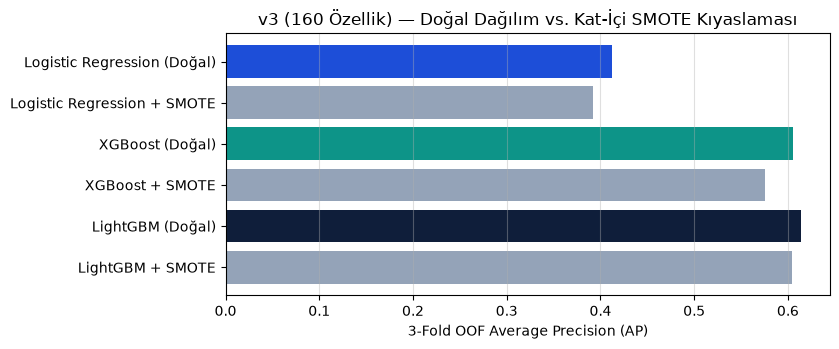

In [4]:
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

X_tr_np = train_df[fcols].to_numpy(np.float32)
folds3 = list(StratifiedKFold(3, shuffle=True, random_state=42).split(X_tr_np, y_tr))

def eval_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    bi = int(np.argmax(2*p[:-1]*r[:-1]/(p[:-1]+r[:-1]+1e-12)))
    pr = s >= t[bi]
    return dict(OOF_AP=round(average_precision_score(y, s), 4), ROC_AUC=round(roc_auc_score(y, s), 4),
                F1=round(f1_score(y, pr), 4), Precision=round(precision_score(y, pr), 4),
                Recall=round(recall_score(y, pr), 4), FP=int(((y==0)&pr).sum()))

cands = [
    ('Logistic Regression (Doğal)', lambda: ImbPipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('clf', LogisticRegression(max_iter=500, C=0.5))])),
    ('Logistic Regression + SMOTE', lambda: ImbPipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('sm', SMOTE(sampling_strategy=0.5, random_state=42)), ('clf', LogisticRegression(max_iter=500, C=0.5))])),
    ('XGBoost (Doğal)', lambda: XGBClassifier(n_estimators=400, learning_rate=0.035, max_depth=6, min_child_weight=10, subsample=0.85, colsample_bytree=0.5, tree_method='hist', random_state=42, n_jobs=4, eval_metric='logloss')),
    ('XGBoost + SMOTE', lambda: ImbPipeline([('imp', SimpleImputer(strategy='median')), ('sm', SMOTE(sampling_strategy=0.5, random_state=42)), ('clf', XGBClassifier(n_estimators=400, learning_rate=0.035, max_depth=6, min_child_weight=10, subsample=0.85, colsample_bytree=0.5, tree_method='hist', random_state=42, n_jobs=4, eval_metric='logloss'))])),
    ('LightGBM (Doğal)', lambda: LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=40, min_child_samples=50, subsample=0.85, subsample_freq=1, colsample_bytree=0.65, random_state=42, n_jobs=4, verbose=-1)),
    ('LightGBM + SMOTE', lambda: ImbPipeline([('imp', SimpleImputer(strategy='median')), ('sm', SMOTE(sampling_strategy=0.5, random_state=42)), ('clf', LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=40, min_child_samples=50, subsample=0.85, subsample_freq=1, colsample_bytree=0.65, random_state=42, n_jobs=4, verbose=-1))])),
]
smote_rows = []
for ad, fn in cands:
    oof = np.zeros(len(y_tr))
    for tr, va in folds3:
        m = fn(); m.fit(X_tr_np[tr], y_tr[tr]); oof[va] = m.predict_proba(X_tr_np[va])[:, 1]
    smote_rows.append({'Model / Dengeleme': ad, **eval_f1(y_tr, oof)})
smote_df = pd.DataFrame(smote_rows)
display(smote_df)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
cols_c = ['#1D4ED8', '#94A3B8', '#0D9488', '#94A3B8', '#0F1E3A', '#94A3B8']
ax.barh(smote_df['Model / Dengeleme'][::-1], smote_df['OOF_AP'][::-1], color=cols_c[::-1])
ax.set_xlabel('3-Fold OOF Average Precision (AP)')
ax.set_title('v3 (160 Özellik) — Doğal Dağılım vs. Kat-İçi SMOTE Kıyaslaması')
ax.grid(axis='x', alpha=0.4)
plt.tight_layout(); plt.show()

## 4. 4 Aileli Kalibre Stacking Mimarisi ve Bağımsız 5-Fold OOF Sonuçları
Eğitilmiş final modeli (`ensemble_v3.joblib`) inceleyerek içindeki 4 farklı aileyi (**LightGBM, CatBoost, XGBoost, RankGauss MLP**) ve logit-uzayı Sigmoid/Platt meta-öğrenicisini doğruluyoruz.

In [5]:
model = joblib.load(EXP / 'ensemble_v3.joblib')
print('Temel Model Aileleri:', list(model.named_estimators_.keys()))
print('Meta-Öğrenici (Kalibrasyon):', model.final_estimator_)
print('decision_function var mı? (False olmalı):', hasattr(model, 'decision_function'))

cv_df = pd.read_csv(EXP / 'model_karsilastirma.csv')
display(cv_df)

Temel Model Aileleri: ['lgbm', 'catboost', 'xgboost', 'mlp']
Meta-Öğrenici (Kalibrasyon): Pipeline(steps=[('clip',
                 FunctionTransformer(func=<function clip at 0x0000020B4E60BDF0>,
                                     kw_args={'a_max': 0.999999,
                                              'a_min': 1e-06})),
                ('logit', FunctionTransformer(func=<ufunc 'logit'>)),
                ('cal',
                 CalibratedClassifierCV(cv=3,
                                        estimator=LogisticRegression(C=0.5,
                                                                     max_iter=1000)))])
decision_function var mı? (False olmalı): False


,Model,CV_Folds,OOF_AP,OOF_ROC_AUC,OOF_F1,OOF_Precision,OOF_Recall,OOF_FP,OOF_FN
0,lgbm,5,0.63275,0.90780,0.5801,0.6182,0.5465,966,1298
1,catboost,5,0.62082,0.90091,0.5738,0.6041,0.5465,1025,1298
2,xgboost,5,0.61942,0.90413,0.5632,0.5915,0.5374,1062,1324
3,mlp,5,0.50656,0.84909,0.4845,0.4803,0.4888,1514,1463
4,Calibrated Stacking v3 (LGBM + CatBoost + XGBo...,5,0.63565,0.90847,0.5775,0.6068,0.5510,1022,1285
